Diagnoses discontinuities ("jumps") in the accumulated mirror-shape gradient from an optimization run. Sums the per-step gradient (`gradient.csv`) into a total mirror shift, flags outlier points via the second derivative + IQR, splices out those discontinuous segments, fits a polynomial to what remains, and compares the reconstructed final mirror shape against the target mirror.

Moved here from `adjoint/` (which no longer has an `adjoint.py`) so it can import directly from this folder's `adjoint_field.py` (renamed from `adjoint.py` during a later repo cleanup), and points at the existing run `int_para_to_para/runs/int_para2para_d_lr_1e-10_ft_0.05_fi_0.045_nr_1000_rmx_5_nzf_501_dz_0.02_L_0_st_1000_sk_1_fn_25/`.

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from adjoint_field import *

font = {"size": 24}

plt.rc("font", **font)
plt.rcParams["figure.figsize"] = (16, 9)
plt.rcParams["lines.linewidth"] = 3

In [ ]:
# read in gradient data
run_dir = 'int_para_to_para/runs/int_para2para_d_lr_1e-10_ft_0.05_fi_0.045_nr_1000_rmx_5_nzf_501_dz_0.02_L_0_st_1000_sk_1_fn_25'
data = np.genfromtxt(run_dir + '/gradient.csv', delimiter=',')

In [ ]:
params=initialize_variables_from_file(run_dir + '/d_lr_1e-10_ft_0.05_fi_0.045_nr_1000_rmx_5_nzf_501_dz_0.02_L_0_st_1000_sk_1_fn_25.txt')

In [ ]:
f = params["f_targ"]  # focal length of lens
ell = 0  # order of Bessel J function
mir_i = params["f_init"]  # initial mirror focal length
conic = params["conic"]

# Beam Parameters
wl = params["wl"]  # wavelength
k0 = 2 * np.pi / wl  # k=2*pi/wavelength
fn = params["f_num"]  # f#
w0 = f / (2 * fn)  # initial spot size
rmax = params["r_maxf"] * w0  # the max value of r
nr = params["nr"]  # number of points in r
zR = np.pi * w0**2 / wl  # Initial rayleigh length
wR = 2 / np.pi * fn * wl  # Diffraction limited spot size

# Distance parameters
dz = params["dz"]
nzf = params["nzf"]
zF = np.linspace(f - dz, f + dz, nzf)
fl = len(zF) // 2  # focal length index

# Guess parameters
OoM = math.floor(math.log(w0**2, 10))  # order of magnitude of w0^2
w_guess = 10**OoM  # guess for the spot size
steps = params["steps"]  # max number of steps algorithm is allowed
lr = params["lr"]  # learning rate
tol = params["tol"]  # tolerance
delta = params["delta"]  # weighting function in r

################################################

# Hankel
r, k, T_R2K, T_K2R = DHTsetup(nr, rmax, ell)

In [69]:
grad=-1*data*lr
total_grad=np.sum(grad, axis=0)

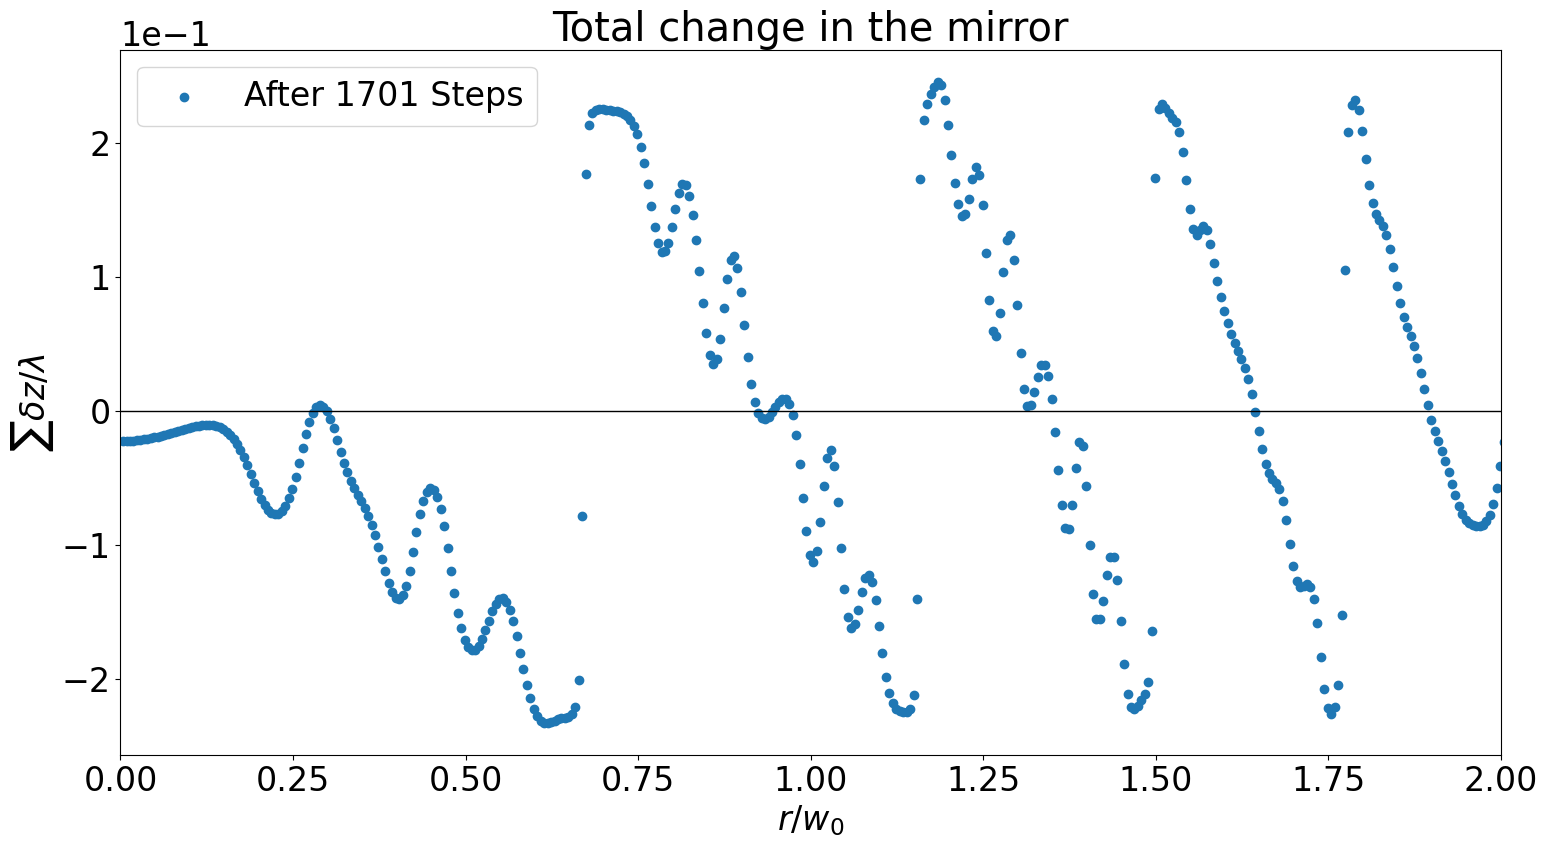

In [70]:
plt.scatter(
        r / w0, total_grad/wl, label="After %d Steps" % (len(data))
    )
    # plt.xlim((0,2*w0))
plt.title("Total change in the mirror")
plt.xlabel(r"$r/w_0$")
plt.ylabel(r"$\sum\delta z/\lambda$")
plt.ticklabel_format(axis="both", style="sci", scilimits=(0, 0))
# plt.axvline(w0,label='$w_0$',linestyle='--',c='k')
plt.axhline(0, c="k", linewidth=1)
plt.xlim((0,2))
plt.tight_layout()
plt.legend()
plt.savefig('total_grad.png')

In [71]:
ddr = np.gradient(total_grad, r)
d2dr = np.gradient(ddr, r)

Q1 = np.percentile(d2dr, 5)
Q3 = np.percentile(d2dr, 95)
IQR = Q3 - Q1
outlier_points = np.where((d2dr < (Q1 - 1.5 * IQR)) | (d2dr > (Q3 + 1.5 * IQR)))

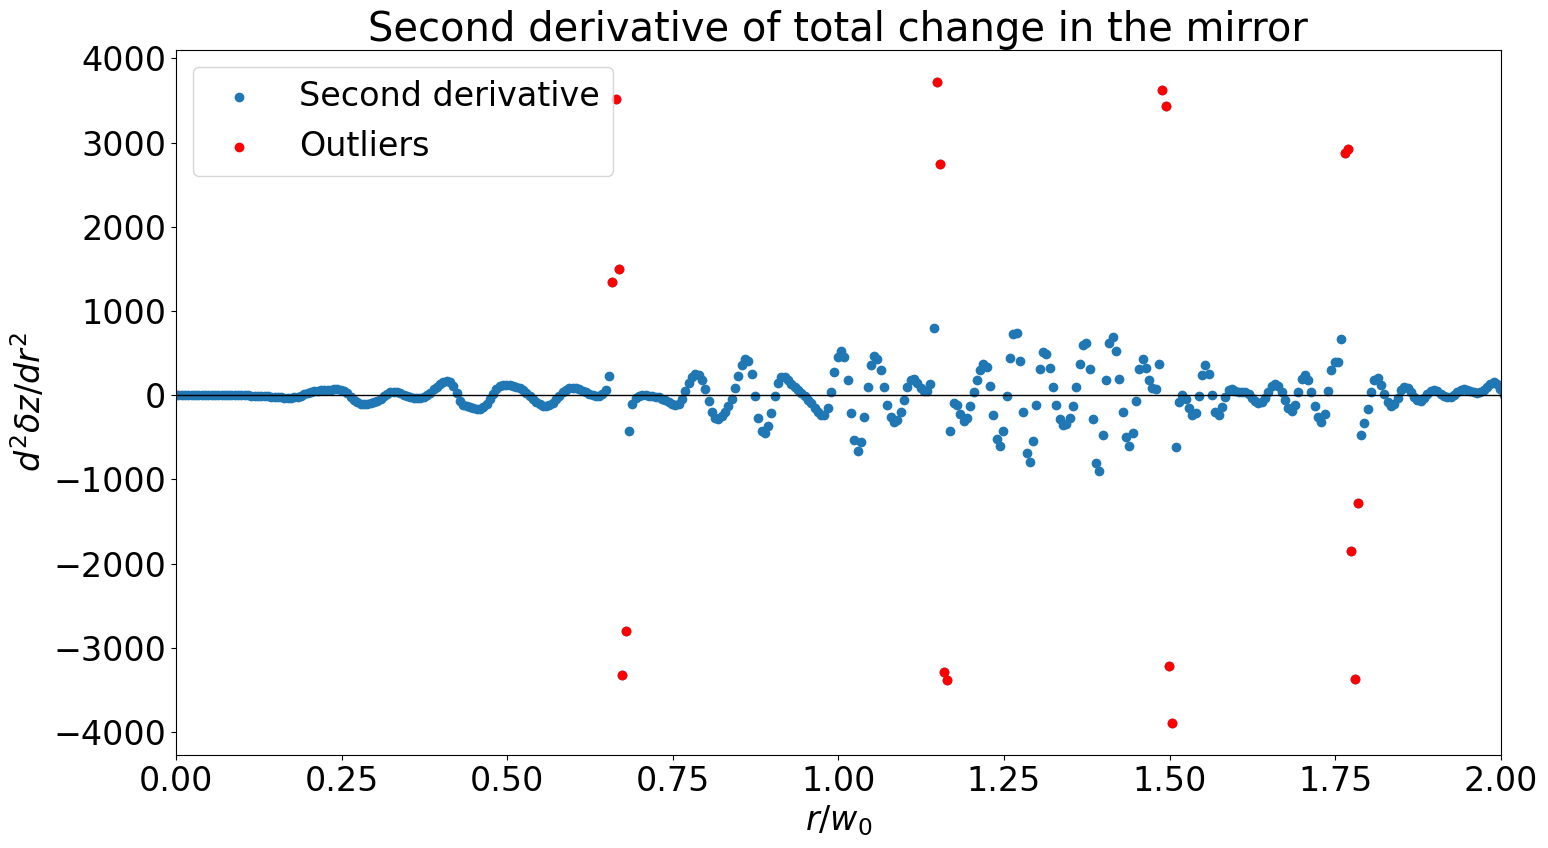

In [72]:
plt.scatter(
        r / w0, d2dr, label="Second derivative"
    )

plt.scatter(
    r[outlier_points] / w0, d2dr[outlier_points], c="r", label="Outliers"
)
plt.xlim((0,2))
plt.title("Second derivative of total change in the mirror")
plt.xlabel(r"$r/w_0$")
plt.ylabel(r"$d^2\delta z/dr^2$")
plt.axhline(0, c="k", linewidth=1)
plt.legend()
plt.tight_layout()
plt.savefig('second_derivative.png')
plt.show()

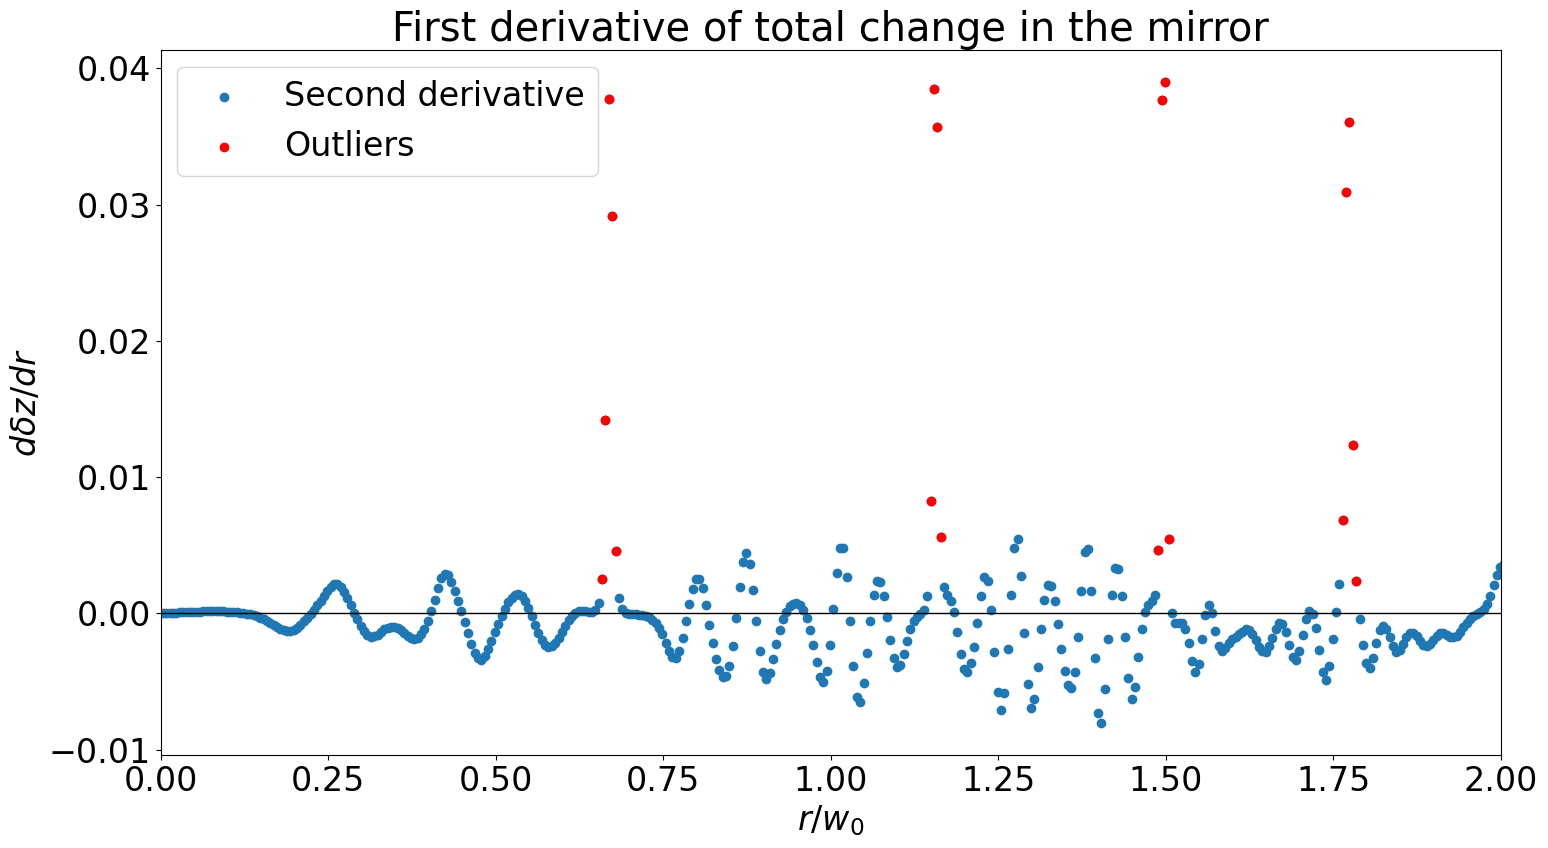

In [73]:
plt.scatter(
        r / w0, ddr, label="Second derivative"
    )

plt.scatter(
    r[outlier_points] / w0, ddr[outlier_points], c="r", label="Outliers"
)
plt.xlim((0,2))
plt.title("First derivative of total change in the mirror")
plt.xlabel(r"$r/w_0$")
plt.ylabel(r"$d\delta z/dr$")
plt.axhline(0, c="k", linewidth=1)
plt.legend()
plt.tight_layout()
plt.savefig('first_derivative.png')
plt.show()

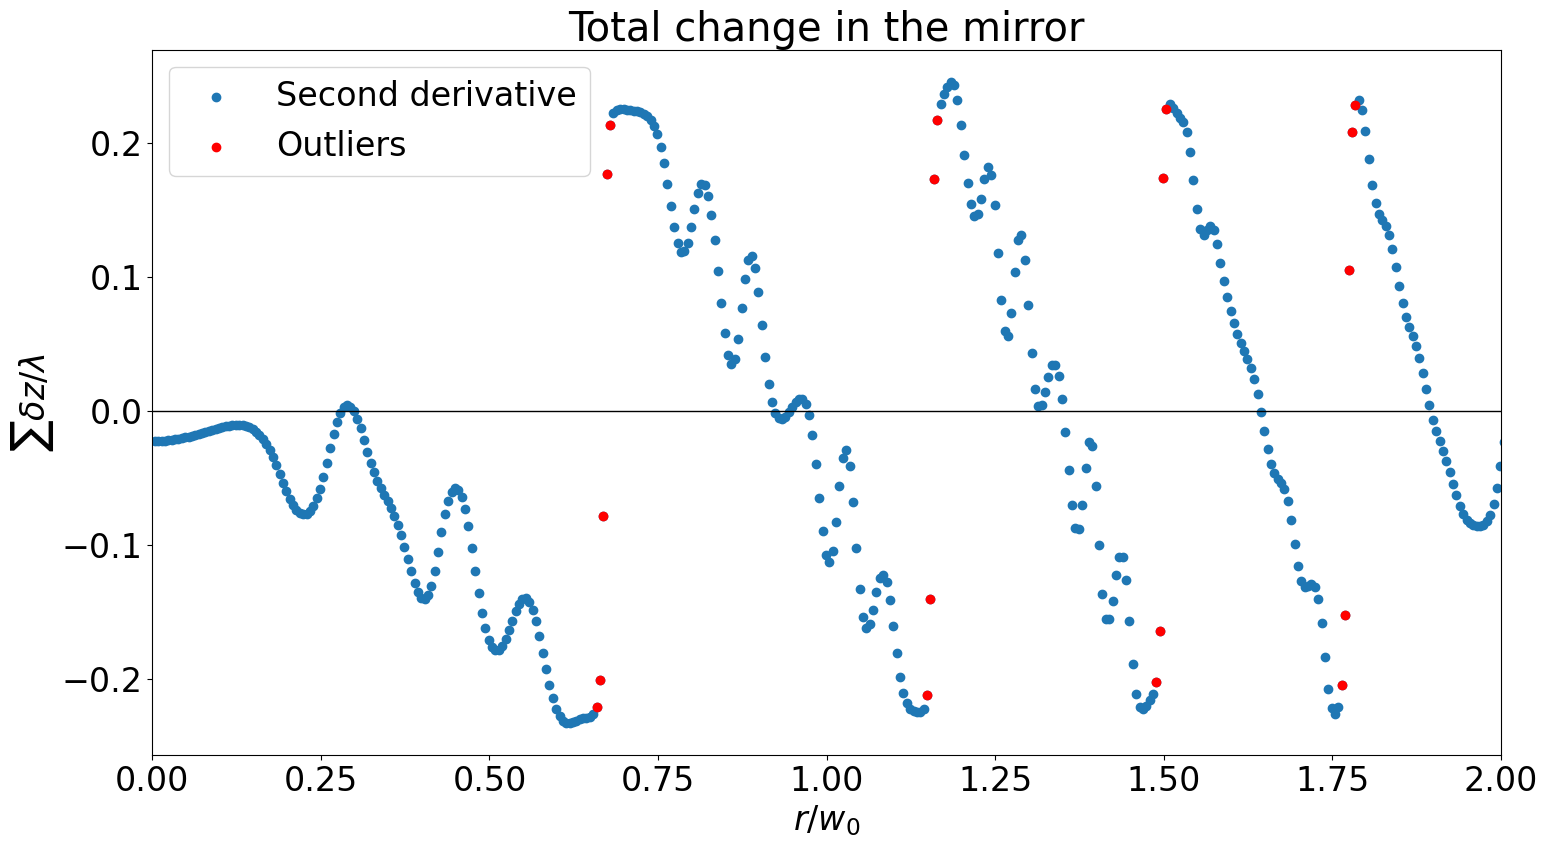

In [74]:
plt.scatter(
        r / w0, total_grad/wl, label="Second derivative"
    )

plt.scatter(
    r[outlier_points] / w0, total_grad[outlier_points]/wl, c="r", label="Outliers"
)
plt.xlim((0,2))
plt.title("Total change in the mirror")
plt.xlabel(r"$r/w_0$")
plt.ylabel(r"$\sum{\delta z}/\lambda$")
plt.axhline(0, c="k", linewidth=1)
plt.legend()
plt.tight_layout()
plt.savefig('outliers_grad.png')
plt.show()

In [75]:
# identify the consecutive sequences within outlier_points
outlier_indices = outlier_points[0]
outlier_indices = np.sort(outlier_indices)
diff = np.diff(outlier_indices)
diff = np.insert(diff, 0, 0)
diff = np.append(diff, 0)
diff = np.where(diff > 1)
diff = np.array(diff).flatten()
diff = np.split(outlier_indices, diff)
print(diff)

#create a new array that is the first and last index of each sequence and flatten into 1D array
indices = np.array([np.array([i[0], i[-1]]) for i in diff]).flatten()
#insert the first and last index of the original array
indices = np.insert(indices, 0, 0)
indices = np.append(indices, len(total_grad))
print(indices)

[array([131, 132, 133, 134, 135]), array([229, 230, 231, 232]), array([297, 298, 299, 300]), array([352, 353, 354, 355, 356])]
[   0  131  135  229  232  297  300  352  356 1000]


In [76]:
total_grad[232]-total_grad[229]

4.2893215803760224e-07

In [77]:
zm_r = create_starting_optic(r, 2 * mir_i, k=conic)  # initial mirror
zm_t = create_starting_optic(r, 2 * f)  # target mirror

In [78]:
# for outlier_indices splice total_grad so that its from the first index to second index, third to fourth index, etc. and store into 1d array
spliced_grad = []
spliced_r = []
spliced_zm_r = []
spliced_zm_t= []
for i in range(0, len(indices), 2):
    spliced_grad = np.append(spliced_grad, total_grad[indices[i]:indices[i+1]]-(i*2.5e-7))
    spliced_r = np.append(spliced_r, r[indices[i]:indices[i+1]])
    spliced_zm_r = np.append(spliced_zm_r, zm_r[indices[i]:indices[i+1]])
    spliced_zm_t = np.append(spliced_zm_t, zm_t[indices[i]:indices[i+1]])
spliced_grad=np.array(spliced_grad).flatten()
spliced_r=np.array(spliced_r).flatten()

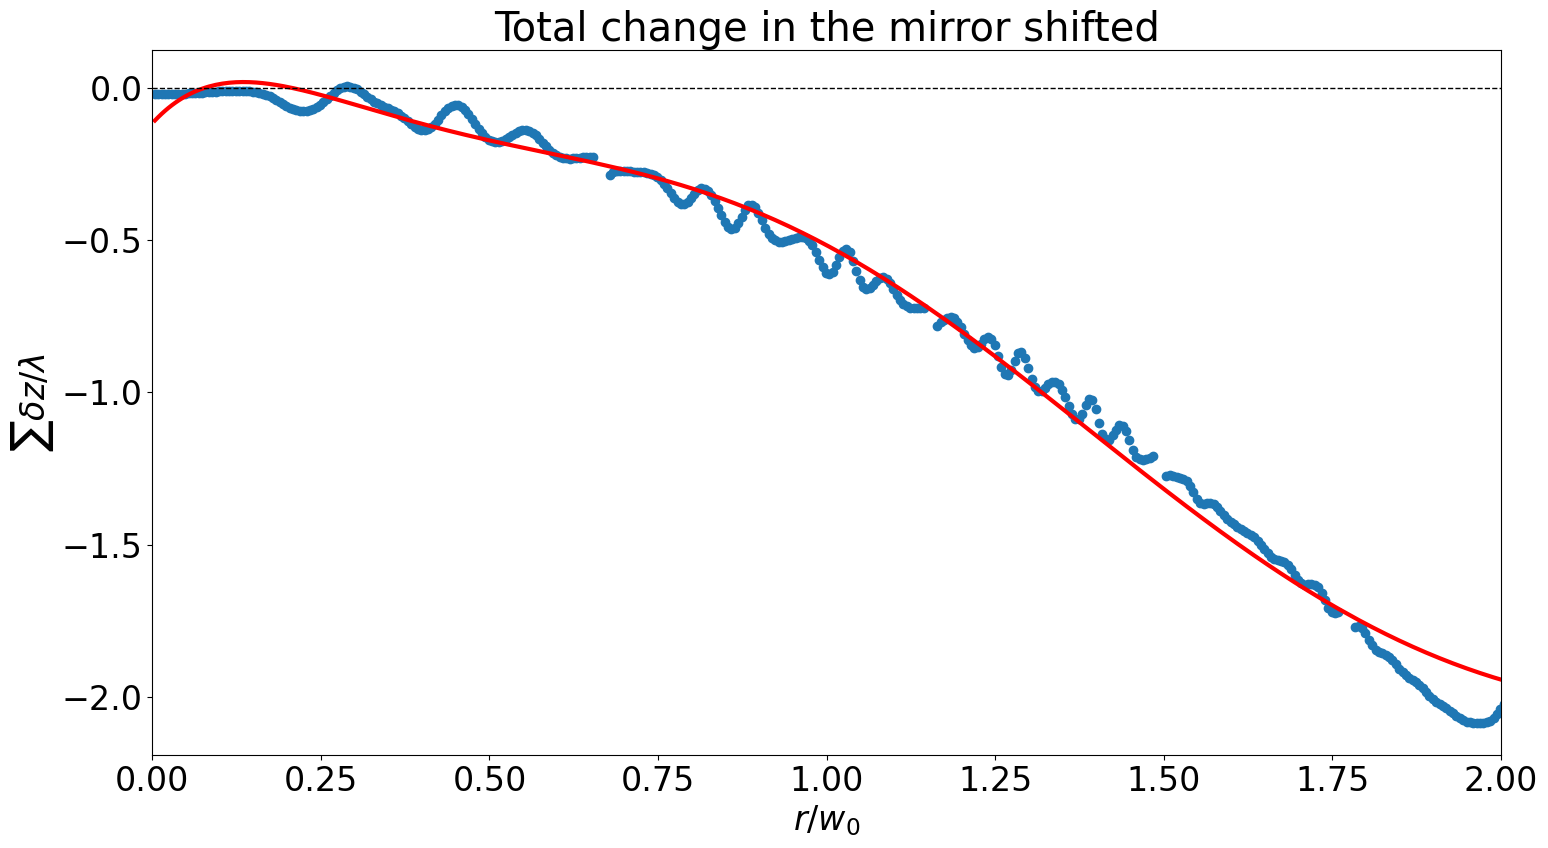

In [79]:

plt.scatter(
        spliced_r / w0, spliced_grad/wl, label="After %d Steps" % (len(data))
    )

# fit a polynomial to the spliced data and plot it
p = np.poly1d(np.polyfit(spliced_r, spliced_grad, 10))
plt.plot(spliced_r/w0, p(spliced_r)/wl, label="Fitted polynomial", c="r")

plt.xlim((0,2))
plt.title("Total change in the mirror shifted")
plt.xlabel(r"$r/w_0$")
plt.ylabel(r"$\sum\delta z/\lambda$")
plt.ticklabel_format(axis="both", style="sci", scilimits=(0, 0))
plt.axhline(0, c="k", linewidth=1,linestyle='--')
plt.tight_layout()
# plt.savefig('shifted_grad.png')
plt.show()

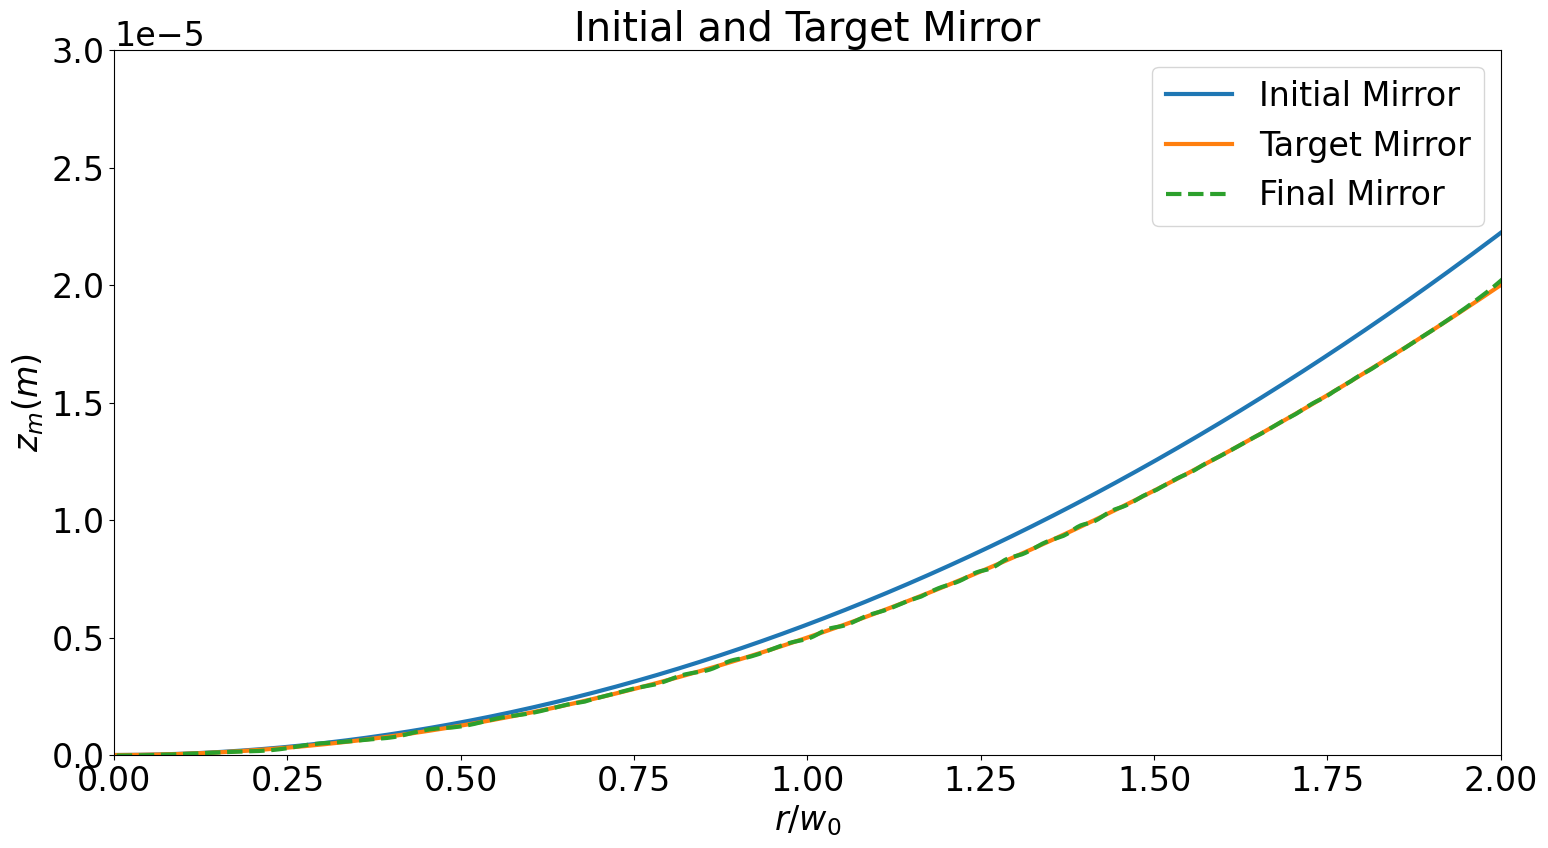

In [82]:
# plot target and initial mirror
plt.plot(r / w0, zm_r, label="Initial Mirror")
plt.plot(r / w0, zm_t, label="Target Mirror")
plt.plot(spliced_r / w0, spliced_zm_r+spliced_grad, label="Final Mirror",linestyle='--')
#
plt.title("Initial and Target Mirror")
plt.xlabel(r"$r/w_0$")
plt.ylabel(r"$z_m (m)$")
#set y-axis to be in scientific notation
plt.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
plt.legend()
plt.xlim((0,2))
plt.ylim((0, 3e-5))
plt.tight_layout() 
plt.savefig('mirror_shift_comp.png')

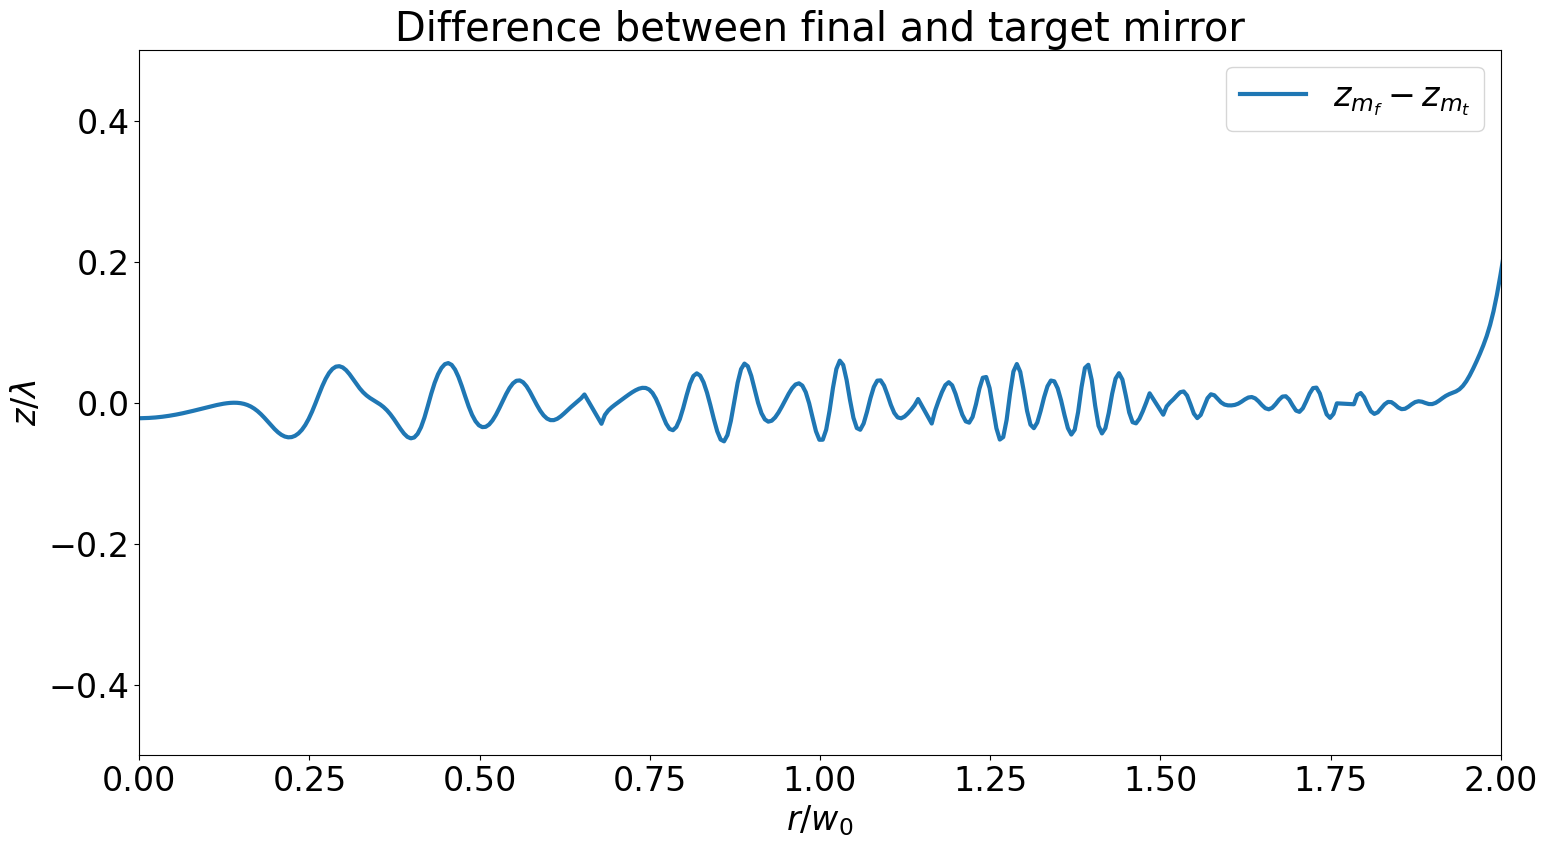

In [83]:
#plot the difference between the final mirror and the target mirror

plt.plot(spliced_r / w0, (spliced_zm_r+spliced_grad-spliced_zm_t)/1e-6, label=r"$z_{m_f}-z_{m_t}$")
plt.title("Difference between final and target mirror")
plt.xlabel(r"$r/w_0$")
plt.ylabel(r"$z/\lambda$")
plt.legend()
plt.xlim((0,2))
plt.ylim((-0.5,0.5))
plt.tight_layout()
plt.savefig('mirror_difference.png')
plt.show()